# Segundo Parcial — INF672 Machine Learning
## Análisis de sentimiento de reseñas de cine con Regresión Logística

**Dataset:** IMDB Dataset of 50K Movie Reviews  


## 1. Carga y exploración



In [20]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from IPython.display import display

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
nltk.download("stopwords")
pd.set_option("display.max_colwidth", 220)
RANDOM_STATE = 42

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [21]:

df = pd.read_csv("IMDB Dataset.csv")
print("Dimensiones del dataset:", df.shape)
display(df.head())

Dimensiones del dataset: (50000, 2)


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its br...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />Th...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue is witty and the char...",positive
3,"Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to b...",negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be telling us what money, power and success...",positive


Columnas: ['review', 'sentiment']

Distribución de clases:


,cantidad
sentiment,
positive,25000
negative,25000



Valores nulos:


,nulos
review,0
sentiment,0



Reseñas duplicadas: 418


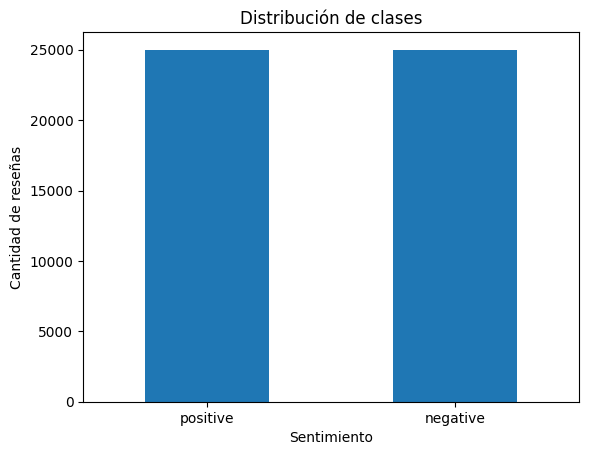

In [22]:
print("Columnas:", df.columns.tolist())

print("\nDistribución de clases:")
display(df["sentiment"].value_counts().to_frame("cantidad"))

print("\nValores nulos:")
display(df.isnull().sum().to_frame("nulos"))

duplicados = df.duplicated(subset=["review"]).sum()
print("\nReseñas duplicadas:", duplicados)

df["sentiment"].value_counts().plot(kind="bar")
plt.title("Distribución de clases")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de reseñas")
plt.xticks(rotation=0)
plt.show()

### Decisión sobre los duplicados

El dataset no presenta valores nulos, pero sí contiene reseñas duplicadas.  
Voy a **eliminar los duplicados antes de separar entrenamiento y prueba**. La razón es evitar que una misma reseña aparezca en ambos conjuntos, porque eso podría producir una evaluación demasiado optimista: el modelo prácticamente estaría viendo en prueba un texto que ya conoció durante el entrenamiento.

Dimensiones después de eliminar duplicados: (49582, 3)


,count,mean,median,std,min,max
sentiment,,,,,,
negative,24698,229.60,174.0,165.10,4,1522
positive,24884,233.09,172.0,177.69,10,2470


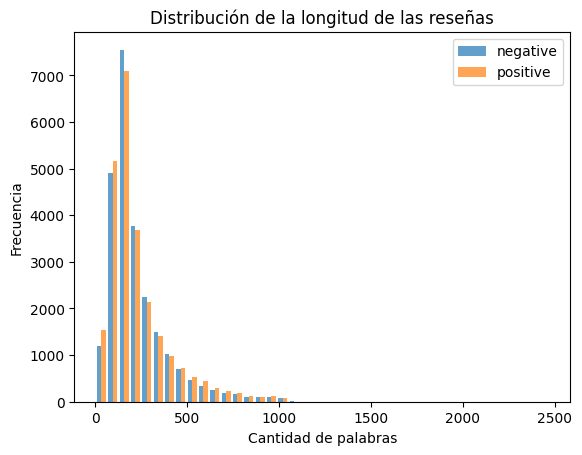

In [23]:
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

df["review_length"] = df["review"].str.split().str.len()

print("Dimensiones después de eliminar duplicados:", df.shape)

resumen_longitud = (
    df.groupby("sentiment")["review_length"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)
display(resumen_longitud)

long_neg = df.loc[df["sentiment"] == "negative", "review_length"]
long_pos = df.loc[df["sentiment"] == "positive", "review_length"]

plt.hist([long_neg, long_pos], bins=40, label=["negative", "positive"], alpha=0.7)
plt.title("Distribución de la longitud de las reseñas")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

### Interpretación de la longitud

Las dos clases tienen distribuciones de longitud bastante parecidas. Por eso, la cantidad de palabras de una reseña no parece ser suficiente para decidir por sí sola si una opinión es positiva o negativa. El contenido de las palabras será mucho más importante que la longitud.

## 2. Preprocesamiento del texto

Antes de limpiar el texto conviene comprobar qué elementos “sucios” realmente aparecen. En este dataset se revisan etiquetas HTML, URLs y correos electrónicos. Los números se cuentan como referencia, pero no se consideran automáticamente “basura”, porque expresiones como `10/10` pueden tener información de sentimiento.

In [24]:
patrones = {
    "Etiquetas HTML": r"<[^>]+>",
    "Saltos <br />": r"<br\s*/?>",
    "URLs": r"https?://\S+|www\.\S+",
    "Correos": r"\b[\w\.-]+@[\w\.-]+\.\w+\b",
    "Números": r"\b\d+\b"
}

conteos_suciedad = {
    nombre: int(df["review"].str.contains(patron, regex=True, case=False, na=False).sum())
    for nombre, patron in patrones.items()
}

display(pd.Series(conteos_suciedad, name="reseñas_que_contienen_el_elemento").to_frame())

print("\nEjemplos con etiquetas HTML:")
display(
    df.loc[df["review"].str.contains(r"<br\s*/?>", regex=True, case=False, na=False),
           ["review", "sentiment"]].head(3)
)

,reseñas_que_contienen_el_elemento
Etiquetas HTML,28968
Saltos <br />,28966
URLs,195
Correos,46
Números,25686



Ejemplos con etiquetas HTML:


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its br...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />Th...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue is witty and the char...",positive


### Stopwords y palabras de negación

Las stopwords son palabras muy frecuentes que normalmente aportan poca información, por ejemplo `the`, `a`, `is` o `and`.

Sin embargo, en análisis de sentimiento **no conviene eliminar todas las stopwords de forma automática**. Palabras como `not`, `no`, `nor` y `but` pueden cambiar el sentido de una oración:

- `good` expresa una idea positiva.
- `not good` expresa lo contrario.
- `but` suele introducir un contraste importante.

Por eso conservaré `not`, `no`, `nor` y `but`. Además, transformaré contracciones con `n't` a `not` antes de eliminar signos. Después se aplicará **stemming** con `PorterStemmer`, siguiendo la idea trabajada en clase.

In [25]:
# Stopwords en inglés
stop_words = set(stopwords.words("english"))

# Conservamos palabras importantes para el sentimiento
for palabra in ["not", "no", "nor", "but"]:
    stop_words.discard(palabra)

# Stemming
stemmer = PorterStemmer()

def preprocesar_texto(texto):
    texto = str(texto).lower()

    # Eliminar etiquetas HTML
    texto = re.sub(r"<br\s*/?>", " ", texto)
    texto = re.sub(r"<[^>]+>", " ", texto)

    # Eliminar URLs
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)

    # Eliminar correos electrónicos
    texto = re.sub(r"\b[\w\.-]+@[\w\.-]+\.\w+\b", " ", texto)

    # Convertir contracciones negativas
    # Ejemplo: isn't -> is not
    texto = re.sub(r"n['’]t\b", " not", texto)

    # Dejar solamente letras y espacios
    texto = re.sub(r"[^a-z\s]", " ", texto)

    # Separar el texto en palabras
    tokens = texto.split()

    # Eliminar stopwords y aplicar stemming
    tokens_limpios = [
        stemmer.stem(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]

    return " ".join(tokens_limpios)

### Muestra inicial de 5 000 reseñas

Para mantener el trabajo manejable, se toma una muestra de **2 500 reseñas positivas y 2 500 negativas**. Esto conserva un equilibrio perfecto entre las dos clases.

In [26]:
muestra = (
    df.groupby("sentiment", group_keys=False)
      .sample(n=2500, random_state=RANDOM_STATE)
      .sample(frac=1, random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

print("Tamaño de la muestra:", muestra.shape)
display(muestra["sentiment"].value_counts().to_frame("cantidad"))

muestra["clean_review"] = muestra["review"].apply(preprocesar_texto)

display(
    muestra[["review", "clean_review", "sentiment"]].head(5)
)

Tamaño de la muestra: (5000, 3)


,cantidad
sentiment,
negative,2500
positive,2500


,review,clean_review,sentiment
0,"I would be one of the few people who owns a copy of this classic. But i dont only own 1, i actually own 2. Its THAT good.<br /><br />Well, when i say good, i mean bad. But i will try to do a thorough review. I even w...",would one peopl own copi classic but dont actual good well say good mean bad but tri thorough review even watch born ninja one review mention compar born ninja actual wors but not quit funni ever funni everyth movi p...,negative
1,"Believe it or not, at 12 minutes, this film (for 1912) is a full-length film. Very, very few films were longer than that back then, but that is definitely NOT what sets this odd little film apart from the rest! No, w...",believ not minut film full length film film longer back but definit not set odd littl film apart rest no differ actor except one frog bug ye bug simpl littl domest comedi could look much like product star like chapli...,positive
2,"Alain Delon visits swift, sure vengeance on the ruthless crime family that employed him as a hit-man in the Duccio Tessari thriller ""Big Guns"" after they accidentally murder his wife and child. Tessari and scenarists...",alain delon visit swift sure vengeanc ruthless crime famili employ hit man duccio tessari thriller big gun accident murder wife child tessari scenarist roberto gandu ugo liberator minut pray second die franco verucci...,positive
3,"I rented this by mistake. I thought, after a cursory examination of the box, that this was a time-travel/sci-fi story. Instead, it's a ""Christian"" story, and I suppose is fairly typical example. If you are sold on th...",rent mistak thought cursori examin box time travel sci fi stori instead christian stori suppos fairli typic exampl sold messag probabl overlook awkward plot act etc but found rather pain admit bother rewrit histori s...,negative
4,"I realize it's a small statistical sampling (8 votes as of this posting), but 5.9 out of 10? I'm giving this movie a 3 and even that's generous. I've tried to watch this movie three times now (the Saturday night 9 p....",realiz small statist sampl vote post but give movi even gener tri watch movi three time saturday night premier scifi channel saturday night thursday night broadcast fallen asleep three time movi end leav laundri list...,negative


## 3. División de los datos

Se utilizará:

- **80 %** para entrenamiento.
- **20 %** para prueba.
- `stratify` para conservar la proporción de clases.
- `random_state=42` para que la división sea reproducible.

In [27]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    muestra["clean_review"],
    muestra["sentiment"],
    test_size=0.20,
    stratify=muestra["sentiment"],
    random_state=RANDOM_STATE
)

print("Entrenamiento:", len(X_train_text))
print("Prueba:", len(X_test_text))

print("\nDistribución en entrenamiento:")
display(y_train.value_counts().to_frame("cantidad"))

print("\nDistribución en prueba:")
display(y_test.value_counts().to_frame("cantidad"))

Entrenamiento: 4000
Prueba: 1000

Distribución en entrenamiento:


,cantidad
sentiment,
positive,2000
negative,2000



Distribución en prueba:


,cantidad
sentiment,
negative,500
positive,500


### ¿Por qué el vectorizador se ajusta solamente con entrenamiento?

El método `fit` aprende el vocabulario y, en TF-IDF, también aprende estadísticas como la frecuencia de los términos en los documentos.  
Si se hiciera `fit` usando también el conjunto de prueba, estaríamos dejando que el modelo obtenga información del conjunto que debería permanecer desconocido hasta la evaluación.

Eso se llama **data leakage**. Por esta razón:

1. Se usa `fit_transform()` solamente con `X_train_text`.
2. En `X_test_text` se usa únicamente `transform()`.

Así la evaluación representa mejor lo que ocurriría con reseñas nuevas.

## 4. Vectorización

### Modelo A — Bag of Words

`CountVectorizer` construye un vocabulario y representa cada reseña según cuántas veces aparece cada término.

### Modelo B — TF-IDF

TF-IDF también representa documentos con números, pero no trata todas las palabras igual.  
Una palabra recibe más importancia cuando aparece en una reseña, pero no es demasiado común en todas las reseñas. Las palabras que aparecen en casi todos los textos pierden peso.

En forma simple:

- **TF**: cuántas veces aparece una palabra en un documento.
- **IDF**: reduce el peso de palabras que aparecen en muchos documentos.
- **TF-IDF**: combina ambas ideas para destacar términos más representativos.

In [28]:
count_vectorizer = CountVectorizer(
    max_features=10000,
    min_df=2
)

tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    min_df=2
)

X_train_count = count_vectorizer.fit_transform(X_train_text)
X_test_count = count_vectorizer.transform(X_test_text)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("Bag of Words:")
print("  Train:", X_train_count.shape)
print("  Test :", X_test_count.shape)

print("\nTF-IDF:")
print("  Train:", X_train_tfidf.shape)
print("  Test :", X_test_tfidf.shape)

Bag of Words:
  Train: (4000, 10000)
  Test : (1000, 10000)

TF-IDF:
  Train: (4000, 10000)
  Test : (1000, 10000)


### Experimento con un parámetro: `ngram_range`

Voy a comparar TF-IDF usando:

- `(1, 1)`: solo palabras individuales.
- `(1, 2)`: palabras individuales y pares consecutivos de palabras.

La idea es comprobar si incluir bigramas mejora la clasificación.

In [29]:
resultados_experimento = []

for ngram in [(1, 1), (1, 2)]:
    vectorizador_exp = TfidfVectorizer(
        max_features=10000,
        min_df=2,
        ngram_range=ngram
    )

    X_train_exp = vectorizador_exp.fit_transform(X_train_text)
    X_test_exp = vectorizador_exp.transform(X_test_text)

    modelo_exp = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )
    modelo_exp.fit(X_train_exp, y_train)

    pred_exp = modelo_exp.predict(X_test_exp)

    resultados_experimento.append({
        "ngram_range": str(ngram),
        "accuracy": accuracy_score(y_test, pred_exp),
        "precision": precision_score(y_test, pred_exp, pos_label="positive"),
        "recall": recall_score(y_test, pred_exp, pos_label="positive"),
        "f1": f1_score(y_test, pred_exp, pos_label="positive")
    })

tabla_experimento = pd.DataFrame(resultados_experimento)
display(tabla_experimento.round(4))

f1_uni = tabla_experimento.loc[tabla_experimento["ngram_range"] == "(1, 1)", "f1"].iloc[0]
f1_bi = tabla_experimento.loc[tabla_experimento["ngram_range"] == "(1, 2)", "f1"].iloc[0]

if f1_bi > f1_uni:
    print(
        f"\nEfecto observado: al incluir bigramas el F1 pasó de {f1_uni:.4f} a {f1_bi:.4f}. "
        "La mejora es pequeña, por lo que el beneficio debe compararse con el mayor costo de memoria."
    )
elif f1_bi < f1_uni:
    print(
        f"\nEfecto observado: al incluir bigramas el F1 bajó de {f1_uni:.4f} a {f1_bi:.4f}. "
        "En esta ejecución conviene mantener unigramas."
    )
else:
    print(
        f"\nEfecto observado: el F1 se mantuvo en {f1_uni:.4f}. "
        "No se obtuvo una mejora clara al incluir bigramas."
    )

,ngram_range,accuracy,precision,recall,f1
0,"(1, 1)",0.845,0.8273,0.872,0.8491
1,"(1, 2)",0.851,0.8343,0.876,0.8546



Efecto observado: al incluir bigramas el F1 pasó de 0.8491 a 0.8546. La mejora es pequeña, por lo que el beneficio debe compararse con el mayor costo de memoria.


### Interpretación del experimento

Al utilizar solo unigramas (`ngram_range=(1, 1)`), el modelo obtuvo un **F1 de 0.8491** y una exactitud de **0.8450**. Al incluir también bigramas (`ngram_range=(1, 2)`), el **F1 subió a 0.8546** y la exactitud a **0.8510**.

En esta prueba, incluir pares de palabras mejoró ligeramente el resultado: el F1 aumentó **0.0055** (0.55 puntos porcentuales). Esto sugiere que algunas combinaciones de palabras ayudan a reconocer mejor el sentimiento. Los dos vectorizadores usan `max_features=10000`, por lo que no se puede afirmar solo por este experimento que el segundo haya consumido más memoria: para comprobarlo habría que medir el tiempo y los recursos utilizados. La mejora fue pequeña, pero favorable a los bigramas.


## 5. Entrenamiento y evaluación

Se entrenará una `LogisticRegression` con cada representación y se calcularán:

- exactitud (`accuracy`)
- precisión (`precision`)
- recall
- F1
- matriz de confusión

In [30]:
modelo_count = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

modelo_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

modelo_count.fit(X_train_count, y_train)
modelo_tfidf.fit(X_train_tfidf, y_train)

pred_count = modelo_count.predict(X_test_count)
pred_tfidf = modelo_tfidf.predict(X_test_tfidf)

def obtener_metricas(nombre, y_real, y_pred):
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, pos_label="positive"),
        "Recall": recall_score(y_real, y_pred, pos_label="positive"),
        "F1": f1_score(y_real, y_pred, pos_label="positive")
    }

tabla_resultados = pd.DataFrame([
    obtener_metricas("Bag of Words", y_test, pred_count),
    obtener_metricas("TF-IDF", y_test, pred_tfidf)
])

display(tabla_resultados.round(4))

,Modelo,Accuracy,Precision,Recall,F1
0,Bag of Words,0.839,0.8317,0.850,0.8408
1,TF-IDF,0.845,0.8273,0.872,0.8491


Reporte de clasificación — Bag of Words
              precision    recall  f1-score   support

    negative     0.8466    0.8280    0.8372       500
    positive     0.8317    0.8500    0.8408       500

    accuracy                         0.8390      1000
   macro avg     0.8392    0.8390    0.8390      1000
weighted avg     0.8392    0.8390    0.8390      1000



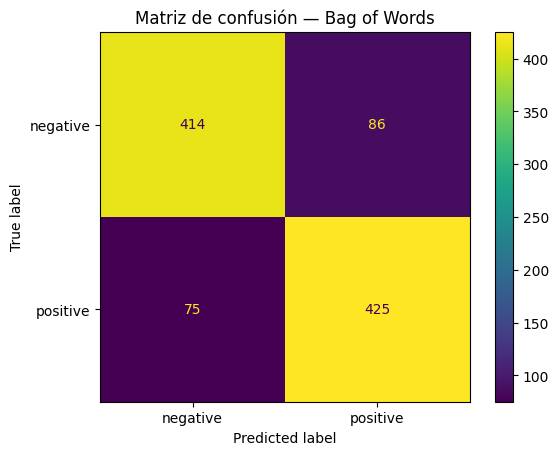

In [31]:
print("Reporte de clasificación — Bag of Words")
print(classification_report(y_test, pred_count, digits=4))

cm_count = confusion_matrix(
    y_test,
    pred_count,
    labels=["negative", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_count,
    display_labels=["negative", "positive"]
)
disp.plot()
plt.title("Matriz de confusión — Bag of Words")
plt.show()

Reporte de clasificación — TF-IDF
              precision    recall  f1-score   support

    negative     0.8647    0.8180    0.8407       500
    positive     0.8273    0.8720    0.8491       500

    accuracy                         0.8450      1000
   macro avg     0.8460    0.8450    0.8449      1000
weighted avg     0.8460    0.8450    0.8449      1000



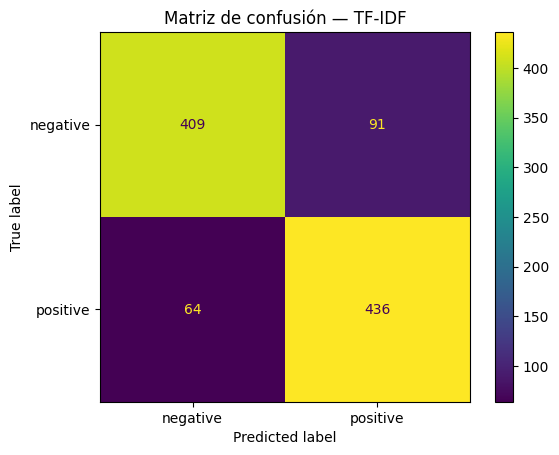

In [32]:
print("Reporte de clasificación — TF-IDF")
print(classification_report(y_test, pred_tfidf, digits=4))

cm_tfidf = confusion_matrix(
    y_test,
    pred_tfidf,
    labels=["negative", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tfidf,
    display_labels=["negative", "positive"]
)
disp.plot()
plt.title("Matriz de confusión — TF-IDF")
plt.show()

In [33]:
# Elegimos por F1; si hubiera empate, se podría revisar también Accuracy y Recall.
mejor_fila = tabla_resultados.sort_values(
    by=["F1", "Accuracy"],
    ascending=False
).iloc[0]

print("Modelo elegido:", mejor_fila["Modelo"])
print(mejor_fila.round(4))

if mejor_fila["Modelo"] == "TF-IDF":
    mejor_modelo = modelo_tfidf
    mejor_vectorizador = tfidf_vectorizer
    X_test_mejor = X_test_tfidf
    pred_mejor = pred_tfidf
    print(
        f"Justificación: elijo TF-IDF porque obtuvo el mayor F1 ({mejor_fila['F1']:.4f}) "
        "y pondera las palabras según su importancia dentro del conjunto de documentos."
    )
else:
    mejor_modelo = modelo_count
    mejor_vectorizador = count_vectorizer
    X_test_mejor = X_test_count
    pred_mejor = pred_count
    print(
        f"Justificación: elijo Bag of Words porque obtuvo el mayor F1 ({mejor_fila['F1']:.4f}) "
        "en esta ejecución. Además, es una representación simple y suficiente para este conjunto de prueba."
    )

Modelo elegido: TF-IDF
Modelo         TF-IDF
Accuracy        0.845
Precision    0.827324
Recall          0.872
F1           0.849075
Name: 1, dtype: object
Justificación: elijo TF-IDF porque obtuvo el mayor F1 (0.8491) y pondera las palabras según su importancia dentro del conjunto de documentos.


### Elección del modelo

La decisión se toma principalmente con **F1**, porque combina precisión y recall. En este problema ambas clases están equilibradas, por lo que la exactitud también es útil para comprobar el rendimiento general.

Si los dos modelos quedan muy cerca, no significa que uno sea claramente superior. En ese caso es válido preferir TF-IDF cuando ofrece un F1 o recall ligeramente mejor, porque reduce el peso de términos demasiado frecuentes y suele ser una representación más informativa para textos.

## 6. Interpretación del mejor modelo

En Regresión Logística, los coeficientes indican qué términos empujan la predicción hacia una clase u otra.

Como las clases se ordenan como `negative` y `positive`:

- coeficientes **positivos grandes** favorecen `positive`;
- coeficientes **negativos grandes en valor absoluto** favorecen `negative`.

In [34]:
print("Orden de clases del modelo:", mejor_modelo.classes_)

nombres_features = mejor_vectorizador.get_feature_names_out()
coeficientes = mejor_modelo.coef_[0]

idx_positivos = np.argsort(coeficientes)[-15:][::-1]
idx_negativos = np.argsort(coeficientes)[:15]

palabras_positivas = pd.DataFrame({
    "palabra": nombres_features[idx_positivos],
    "coeficiente": coeficientes[idx_positivos]
})

palabras_negativas = pd.DataFrame({
    "palabra": nombres_features[idx_negativos],
    "coeficiente": coeficientes[idx_negativos]
})

print("15 términos más asociados a reseñas positivas:")
display(palabras_positivas.round(4))

print("15 términos más asociados a reseñas negativas:")
display(palabras_negativas.round(4))

Orden de clases del modelo: ['negative' 'positive']
15 términos más asociados a reseñas positivas:


,palabra,coeficiente
0,great,4.4214
1,enjoy,3.1741
2,love,3.1181
3,excel,2.8017
4,best,2.7339
5,well,2.3393
6,beauti,2.2372
7,also,2.0695
8,perform,2.0155
9,definit,1.8633


15 términos más asociados a reseñas negativas:


,palabra,coeficiente
0,bad,-5.0427
1,worst,-4.1780
2,aw,-3.0871
3,wast,-2.9093
4,no,-2.8929
5,terribl,-2.7901
6,not,-2.7161
7,bore,-2.5759
8,stupid,-2.5452
9,plot,-2.3883


### ¿Tienen sentido los coeficientes?

Sí. Se espera que entre los términos positivos aparezcan raíces relacionadas con palabras como `great`, `love`, `excellent`, `best`, `perfect` o `enjoy`.  
Entre los negativos suelen aparecer raíces de `bad`, `worst`, `terrible`, `boring`, `waste` o `poor`.

El stemming puede hacer que algunas palabras aparezcan recortadas, por ejemplo `excellent` puede verse como `excel` y `terrible` como `terribl`. Eso es normal.

### Prueba con 3 reseñas propias

Se crean tres reseñas en inglés porque el modelo fue entrenado con reseñas en inglés:

1. claramente positiva;
2. claramente negativa;
3. ambigua o sarcástica.

La tercera es especialmente interesante porque un modelo lineal basado en palabras puede confundirse con el sarcasmo.

In [35]:
resenas_propias = [
    "I absolutely loved this movie. The acting was excellent, the story was moving, and the ending was perfect.",
    "This was one of the worst movies I have seen. The plot was boring, the acting was terrible, and it was a waste of time.",
    "Great, another two hours of my life gone. What a masterpiece of boredom."
]

resenas_propias_limpias = [preprocesar_texto(r) for r in resenas_propias]
X_propias = mejor_vectorizador.transform(resenas_propias_limpias)

pred_propias = mejor_modelo.predict(X_propias)
prob_propias = mejor_modelo.predict_proba(X_propias)

idx_positive = list(mejor_modelo.classes_).index("positive")

tabla_propias = pd.DataFrame({
    "reseña": resenas_propias,
    "predicción": pred_propias,
    "probabilidad_positive": prob_propias[:, idx_positive],
    "probabilidad_negative": 1 - prob_propias[:, idx_positive]
})

display(tabla_propias.round(4))

,reseña,predicción,probabilidad_positive,probabilidad_negative
0,"I absolutely loved this movie. The acting was excellent, the story was moving, and the ending was perfect.",positive,0.9594,0.0406
1,"This was one of the worst movies I have seen. The plot was boring, the acting was terrible, and it was a waste of time.",negative,0.0039,0.9961
2,"Great, another two hours of my life gone. What a masterpiece of boredom.",positive,0.6892,0.3108


### Interpretación de las reseñas propias

Las dos reseñas claras deberían clasificarse con bastante seguridad. La reseña sarcástica puede fallar porque incluye palabras positivas como `great` o `masterpiece`, aunque la intención real sea negativa. Este es un límite típico de Bag of Words/TF-IDF: el modelo reconoce asociaciones entre palabras y clases, pero no comprende realmente la ironía como lo haría una persona.

### Dos reseñas del conjunto de prueba mal clasificadas

A continuación se buscan errores reales del mejor modelo. Además, se muestran dos casos concretos que sirven para explicar por qué un clasificador lineal puede equivocarse.

In [36]:
prob_test = mejor_modelo.predict_proba(X_test_mejor)[:, idx_positive]

resultados_test = pd.DataFrame({
    "review": muestra.loc[X_test_text.index, "review"],
    "real": y_test,
    "predicha": pred_mejor,
    "probabilidad_positive": prob_test
})

errores = resultados_test[resultados_test["real"] != resultados_test["predicha"]].copy()

print("Cantidad de reseñas mal clasificadas:", len(errores))

# Casos concretos encontrados en esta división reproducible.
indices_casos = [2071, 2737]
casos = errores.loc[errores.index.intersection(indices_casos)].copy()

# Si por alguna diferencia de versión alguno no apareciera, completar con otros errores.
if len(casos) < 2:
    faltan = 2 - len(casos)
    adicionales = errores.drop(index=casos.index, errors="ignore").head(faltan)
    casos = pd.concat([casos, adicionales])

display(casos[["review", "real", "predicha", "probabilidad_positive"]])

Cantidad de reseñas mal clasificadas: 155


,review,real,predicha,probabilidad_positive
2737,One of the most interesting things is that this 1988 film is highly touted as an `in-name only' sequel. There's nothing wrong with that except this: The return of Chevy Chase as Ty Webb. This connects the viewer to t...,positive,negative,0.394340
2071,"What starts out as a gentle country yarn, inoffensive and mildly enjoyable romantic tale changes pace as Edward Norton's initially charming Harlan gradually reveals more about himself and things take a turn for the s...",negative,positive,0.634242


### Explicación de los errores

**Caso 1 — índice 2737: reseña positiva predicha como negativa (*Caddyshack II*).**  
La reseña está etiquetada como `positive`, pero contiene críticas y comparaciones desfavorables, por ejemplo sobre personajes que se extrañan y cambios que el autor no aprueba. Es una opinión con elementos mixtos. Por eso el modelo pudo dar demasiado peso a palabras de crítica y clasificarla como `negative` (probabilidad de `positive`: **0.3943**).

**Caso 2 — índice 2071: reseña negativa predicha como positiva (*Down in the Valley*).**  
La reseña comienza con expresiones favorables como `gentle`, `enjoyable` y `charming`, pero luego cambia de tono y presenta críticas a la película. El modelo pudo dejarse influir por esas expresiones positivas y predecir `positive`, aunque su etiqueta real era `negative` (probabilidad de `positive`: **0.6342**).

Estos dos casos muestran una limitación de la Regresión Logística con TF-IDF: se basa en los términos presentes y sus pesos, pero no siempre interpreta bien los cambios de tono ni las opiniones mixtas.


# Conclusiones

1. El dataset original está balanceado entre reseñas positivas y negativas y no presenta valores nulos.
2. Se eliminaron las reseñas duplicadas para evitar posible fuga de información entre entrenamiento y prueba.
3. Las etiquetas HTML como `<br />` aparecen con mucha frecuencia y se eliminaron durante la limpieza.
4. Se conservaron palabras de negación y contraste (`not`, `no`, `nor`, `but`) porque son importantes para interpretar sentimiento.
5. La división se hizo con 80 % para entrenamiento y 20 % para prueba, usando `stratify` y `random_state=42`.
6. Se compararon Bag of Words y TF-IDF con Regresión Logística usando accuracy, precision, recall y F1.
7. También se probó el efecto de incluir bigramas mediante `ngram_range`.
8. Los coeficientes del modelo permiten observar qué palabras están más relacionadas con cada sentimiento.
9. El modelo funciona bien para textos con sentimiento claro, pero puede fallar en reseñas mixtas, con cambios de tono o sarcasmo.
10. Como mejora futura se podrían probar más datos, bigramas con otros parámetros, validación cruzada o modelos capaces de representar mejor el contexto.